# Pjesa I · 3/4: Krijimi i vetive dhe kodimi

**Qëllimi:** nga tabela e pastruar krijojmë veti të reja që ndihmojnë analizën e çmimit për natë. Pas krijimit, notebook-u vazhdon me diskretizimin, binarizimin dhe kodimin.

**Hyrja:** `dataset/listings_clean_full.csv`, tabela e plotë e pastruar nga notebook-u 02 (të gjitha kolonat, para zgjedhjes së 18 kolonave). Ekzekutoni së pari notebook-un 02. Dataset-i origjinal nuk ndryshohet.

In [1]:
import json
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_clean_full.csv").is_file() and (ROOT.parent / "dataset" / "listings_clean_full.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_clean_full.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 02."
df = pd.read_csv(DATA_PATH, low_memory=False, parse_dates=["last_scraped", "last_review"])
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_clean_full.csv | Rreshta: 59,846 | Kolona: 82


## 1. Distanca nga qendra e Londrës

Vendndodhja ndikon fort te çmimi, por `latitude` dhe `longitude` veç e veç nuk kanë kuptim të drejtpërdrejtë. Si qendër marrim **Charing Cross** (51.5073, −0.1276), pikën tradicionale nga e cila maten distancat në Londër. Distancën në km e llogarisim me formulën *haversine*, e cila merr parasysh lakimin e Tokës.

In [2]:
CENTER_LAT, CENTER_LON = 51.5073, -0.1276
EARTH_RADIUS_KM = 6371.0

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))

df["distance_to_center_km"] = haversine_km(df["latitude"], df["longitude"], CENTER_LAT, CENTER_LON)
display(df["distance_to_center_km"].describe().round(2).to_frame())
display(df.groupby(pd.cut(df["distance_to_center_km"], [0, 2, 5, 10, 20, 40]), observed=True)["price"].median().to_frame("çmimi median"))

,distance_to_center_km
count,59846.00
mean,7.66
std,5.14
min,0.03
25%,3.84
50%,6.17
75%,10.55
max,30.70


,çmimi median
distance_to_center_km,
"(0, 2]",324.00
"(2, 5]",220.00
"(5, 10]",159.00
"(10, 20]",123.33
"(20, 40]",101.38


## 2. Përvoja e host-it

`hosts_time_as_host_years` jep vitet e plota, ndërsa `hosts_time_as_host_months` muajt e mbetur (0–11). I bashkojmë në një vlerë të vetme në vite.

In [3]:
df["host_tenure_years"] = df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12
display(df["host_tenure_years"].describe().round(2).to_frame())

,host_tenure_years
count,59846.00
mean,5.37
std,4.06
min,0.00
25%,2.00
50%,4.08
75%,8.83
max,15.67


## 3. Host me shumë listime

`calculated_host_listings_count` numëron listimet e host-it në këtë dataset. E përdorim atë dhe jo `host_listings_count`, sepse ky i fundit vjen nga Airbnb, arrin deri në 5,777 dhe në disa listime është më i vogël se numri i listimeve që shohim vetë në dataset, pra nuk është i qëndrueshëm. Host-i me më shumë se një listim shpesh është menaxher profesional.

In [4]:
df["is_multi_listing_host"] = df["calculated_host_listings_count"].gt(1)
print(f"Listime nga host-e me shumë listime: {df['is_multi_listing_host'].mean():.1%}")
display(df.groupby("is_multi_listing_host")["price"].agg(["count", "median"]).round(2))

Listime nga host-e me shumë listime: 65.5%


,count,median
is_multi_listing_host,,
False,20648,155.0
True,39198,187.0


## 4. Çmimi për person

`price / accommodates` lejon krahasimin e listimeve me kapacitet të ndryshëm. **Kujdes:** kjo veti është krijuar nga çmimi, prandaj nuk duhet përdorur si hyrje e modelit kur çmimi është variabla që parashikohet.

In [5]:
df["price_per_person"] = df["price"] / df["accommodates"]
display(df["price_per_person"].describe().round(2).to_frame())

,price_per_person
count,59846.00
mean,70.99
std,83.94
min,1.50
25%,39.58
50%,55.50
75%,80.83
max,5000.00


## 5. Ditë nga komenti i fundit

Tregon sa aktiv është listimi. Llogaritet nga data e mbledhjes (`last_scraped`) dhe jo nga data e sotme, që rezultati të mos ndryshojë sa herë ekzekutohet notebook-u. Për listimet pa komente vlera mbetet bosh me qëllim: `has_reviews` e mbulon këtë rast.

In [6]:
df["days_since_last_review"] = (df["last_scraped"] - df["last_review"]).dt.days
print(f"Bosh (pa komente): {df['days_since_last_review'].isna().sum():,} | Negative: {int(df['days_since_last_review'].lt(0).sum())}")
display(df["days_since_last_review"].describe().round(1).to_frame())

Bosh (pa komente): 12,226 | Negative: 0


,days_since_last_review
count,47620.0
mean,206.2
std,443.4
min,0.0
25%,16.0
50%,39.0
75%,144.0
max,5289.0


## 6. Kontrolli i vetive të reja

Për secilën veti kontrollojmë mungesat dhe shpërndarjen. `price_per_person` dhe `days_since_last_review` janë shumë asimetrike; kjo trajtohet te transformimi në notebook-un 04.

,bosh
distance_to_center_km,0
host_tenure_years,0
is_multi_listing_host,0
price_per_person,0
days_since_last_review,12226


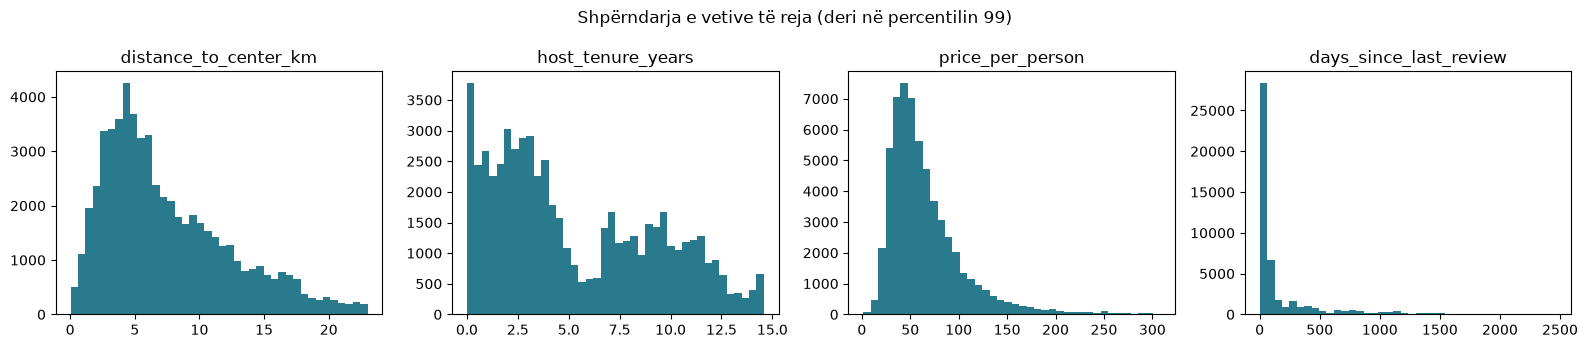

In [7]:
new_features = ["distance_to_center_km", "host_tenure_years", "is_multi_listing_host", "price_per_person", "days_since_last_review"]
display(df[new_features].isna().sum().to_frame("bosh"))
numeric = [col for col in new_features if col != "is_multi_listing_host"]
fig, axes = plt.subplots(1, len(numeric), figsize=(16, 3.5))
for ax, col in zip(axes, numeric):
    values = df[col].dropna()
    values[values.le(values.quantile(0.99))].plot.hist(bins=40, ax=ax, color="#287a8c")
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Shpërndarja e vetive të reja (deri në percentilin 99)")
plt.tight_layout()
plt.show()

## 7. Grupimi i llojit të pronës

`property_type` ka 84 vlera, shumë prej tyre me një ose pak listime. Emri përmban dy informacione: llojin e dhomës dhe llojin e ndërtesës, p.sh. *Private room in rental unit* = `room_type` *Private room* + ndërtesa *rental unit*. Lloji i dhomës ruhet tashmë te `room_type`. Prandaj heqim pjesën e dhomës (*Entire*, *Private room in*, *Shared room in*, *Room in*) dhe grupojmë vetëm **llojin e ndërtesës**. Kështu `property_group` nuk e përsërit `room_type`.

Grupet: **apartment** (banesë, condo, apartament me shërbime, loft), **house** (shtëpi, townhouse, vilë, cottage), **hotel_bnb** (hotel, hostel, aparthotel, bed and breakfast), **guest_suite** (guest suite, guesthouse), **unique** (varkë, kabinë, tendë, kështjellë etj.) dhe **other** për emrat që nuk tregojnë ndërtesën (p.sh. *Entire place*).

In [8]:
ROOM_PREFIX = r"^(entire|private room in|shared room in|room in)\s*"
PROPERTY_GROUPS = {
    "apartment": ["rental unit", "condo", "serviced apartment", "loft", "floor"],
    "house": ["home", "townhouse", "cottage", "bungalow", "villa", "vacation home", "chalet", "earthen home", "cycladic home"],
    "hotel_bnb": ["hotel", "boutique hotel", "aparthotel", "hostel", "bed and breakfast", "casa particular"],
    "guest_suite": ["guest suite", "guesthouse"],
    "unique": ["boat", "houseboat", "tiny home", "cabin", "hut", "shepherd's hut", "camper/rv", "tent", "yurt", "dome",
               "treehouse", "castle", "tower", "lighthouse", "island", "barn", "farm stay", "campsite", "religious building"],
}
group_of = {building: group for group, buildings in PROPERTY_GROUPS.items() for building in buildings}
building = (df["property_type"].str.lower().str.replace("’", "'", regex=False)
            .str.replace(ROOM_PREFIX, "", regex=True).str.strip())
df["property_group"] = building.map(group_of).fillna("other")

print(f"property_type: {df['property_type'].nunique()} vlera → property_group: {df['property_group'].nunique()} grupe")
display(df.groupby("property_group").agg(lloje_origjinale=("property_type", "nunique"), listime=("price", "size"),
                                         cmimi_median=("price", "median")).sort_values("listime", ascending=False))
print("Në 'other':", ", ".join(sorted(df.loc[df["property_group"].eq("other"), "property_type"].unique())))
display(pd.crosstab(df["property_group"], df["room_type"]))

property_type: 84 vlera → property_group: 6 grupe


,lloje_origjinale,listime,cmimi_median
property_group,,,
apartment,14,42143,188.0
house,18,14511,124.0
hotel_bnb,12,2097,126.0
guest_suite,5,760,105.0
unique,32,231,135.0
other,3,104,131.0


Në 'other': Entire home/apt, Entire place, Private room


room_type,Entire home/apt,Hotel room,Private room,Shared room
property_group,,,,
apartment,33275,41,8789,38
guest_suite,329,0,420,11
hotel_bnb,39,93,1878,87
house,6597,0,7887,27
other,55,0,49,0
unique,186,0,44,1


## 8. Pajisjet (`amenities`)

`amenities` është listë JSON e ruajtur si tekst, p.sh. `["Wifi", "Kitchen", ...]`. Notebook-u 02 e numëronte duke numëruar thonjëzat (`"`) dhe duke pjesëtuar me 2. Kjo gabon kur vetë emri i pajisjes përmban thonjëza, p.sh. `"portable stove" stove`. Tani e lexojmë listën me `json.loads` dhe numërojmë elementet.

In [9]:
amenity_lists = df["amenities"].fillna("[]").map(json.loads)
old_count = df["amenities"].fillna("[]").astype(str).str.count('"') // 2
df["amenity_count"] = amenity_lists.map(len)
wrong = old_count.ne(df["amenity_count"])
print(f"Listime me numër të gabuar me metodën e vjetër: {int(wrong.sum())}")
display(pd.DataFrame({"id": df.loc[wrong, "id"], "numri i vjetër": old_count[wrong], "numri i ri": df.loc[wrong, "amenity_count"],
                      "pajisjet me thonjëza": amenity_lists[wrong].map(lambda items: [a for a in items if '"' in a])}))
display(df["amenity_count"].describe().round(1).to_frame())

Listime me numër të gabuar me metodën e vjetër: 3


,id,numri i vjetër,numri i ri,pajisjet me thonjëza
12784,649735327677645022,52,49,"[""Various"" conditioner, ""Various"" body soap, ""..."
14513,689168826164538384,38,37,"[""portable stove"" stove]"
14514,689176861999188774,37,36,"[""portable stove"" electric stove]"


,amenity_count
count,59846.0
mean,32.0
std,15.0
min,0.0
25%,20.0
50%,33.0
75%,43.0
max,99.0


### Flamujt e pajisjeve

Ka mbi 7,000 emra të ndryshëm pajisjesh, sepse host-et i shkruajnë ndryshe (*Wifi*, *Fast wifi – 73 Mbps*, *Pocket wifi*). Për secilin flamur kërkojmë fjalë kyçe në emrat me shkronja të vogla:

- `has_kitchen`: vetëm *Kitchen* ose *Kitchenette*, jo *Outdoor kitchen*;
- `has_washer`: lavatriçe rrobash, jo *Dishwasher*;
- `has_parking`: parking **në pronë** (falas ose me pagesë); parkingu në rrugë ose jashtë pronës nuk llogaritet;
- `has_ac`: *Air conditioning* në çdo formë, *Window AC unit*, *AC - split type*.

Tabela krahason çmimin median të listimeve me dhe pa pajisjen. Ky është krahasim përshkrues, jo shkak-pasojë: p.sh. parkingu është më i shpeshtë larg qendrës, ku çmimet janë më të ulëta.

,% e listimeve,çmimi median me,çmimi median pa
has_wifi,97.5,176.00,126.330
has_kitchen,89.8,184.30,101.000
has_heating,85.1,183.20,123.200
has_washer,84.4,189.00,111.000
has_tv,80.0,199.33,88.790
has_workspace,52.0,185.00,165.000
has_parking,33.0,160.00,180.265
has_ac,14.3,304.00,161.330


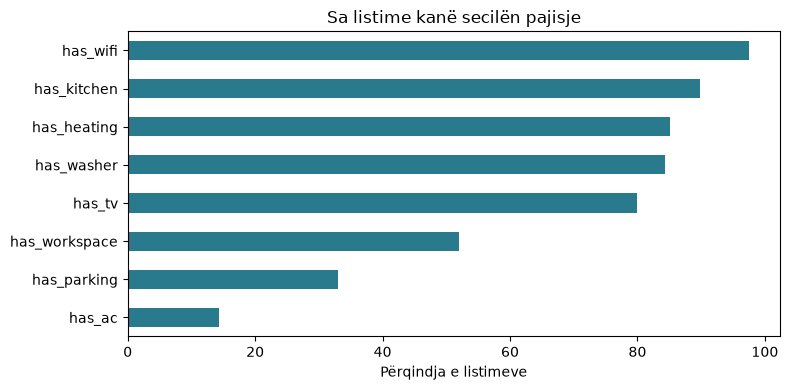

In [10]:
AMENITY_FLAGS = {
    "has_wifi": r"wifi",
    "has_kitchen": r"^(?:kitchen|kitchenette)$",
    "has_ac": r"air conditioning|\bac\b",
    "has_heating": r"heating",
    "has_washer": r"(?<!dish)washer",
    "has_parking": r"parking.*on premises",
    "has_tv": r"\b(?:hd)?tv\b",
    "has_workspace": r"dedicated workspace",
}
amenity_text = amenity_lists.map(lambda items: "\n".join(items).lower())
for flag, pattern in AMENITY_FLAGS.items():
    df[flag] = amenity_text.str.contains(pattern, flags=re.MULTILINE, regex=True)

flags = list(AMENITY_FLAGS)
summary = pd.DataFrame({
    "% e listimeve": df[flags].mean().mul(100).round(1),
    "çmimi median me": [df.loc[df[flag], "price"].median() for flag in flags],
    "çmimi median pa": [df.loc[~df[flag], "price"].median() for flag in flags],
}).sort_values("% e listimeve", ascending=False)
display(summary)
ax = summary["% e listimeve"].sort_values().plot.barh(figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Përqindja e listimeve", ylabel="", title="Sa listime kanë secilën pajisje")
plt.tight_layout()
plt.show()

## 9. Diskretizimi

Diskretizimi e kthen një kolonë numerike në pak grupe. Krahasojmë tri metoda me 4 grupe te `minimum_nights`, `accommodates` dhe `availability_365`:

- **gjerësi e barabartë** (`pd.cut`): intervale me të njëjtën gjatësi;
- **frekuencë e barabartë** (`pd.qcut`): afërsisht i njëjti numër listimesh në çdo grup;
- **sipas domenit**: kufij me kuptim praktik:
  - `minimum_nights`: 1 natë / 2–6 / 7–29 / 30+ (30+ do të thotë qëndrim i gjatë, jo turizëm i shkurtër);
  - `accommodates`: 1 / 2 / 3–4 / 5–6 / 7+ (një person, çift, familje e vogël, familje, grup);
  - `availability_365`: 0 / 1–90 / 91–180 / 181–365 ditë. 90 është kufiri ligjor në Londër për dhënien me qira të një shtëpie të plotë pa leje planifikimi.

`minimum_nights` ka disa vlera që mungojnë pas pastrimit; ato mbeten bosh edhe në grup.

grupe  grupi më i madh (%)  bosh
kolona           metoda                                                 
minimum_nights   gjerësi e barabartë        4                 99.8   298
                 frekuencë e barabartë      3                 69.2   298
                 sipas domenit              4                 47.7   298
accommodates     gjerësi e barabartë        4                 75.0     0
                 frekuencë e barabartë      4                 46.4     0
                 sipas domenit              5                 36.0     0
availability_365 gjerësi e barabartë        4                 42.9     0
                 frekuencë e barabartë      4                 25.1     0
                 sipas domenit              4                 61.2     0

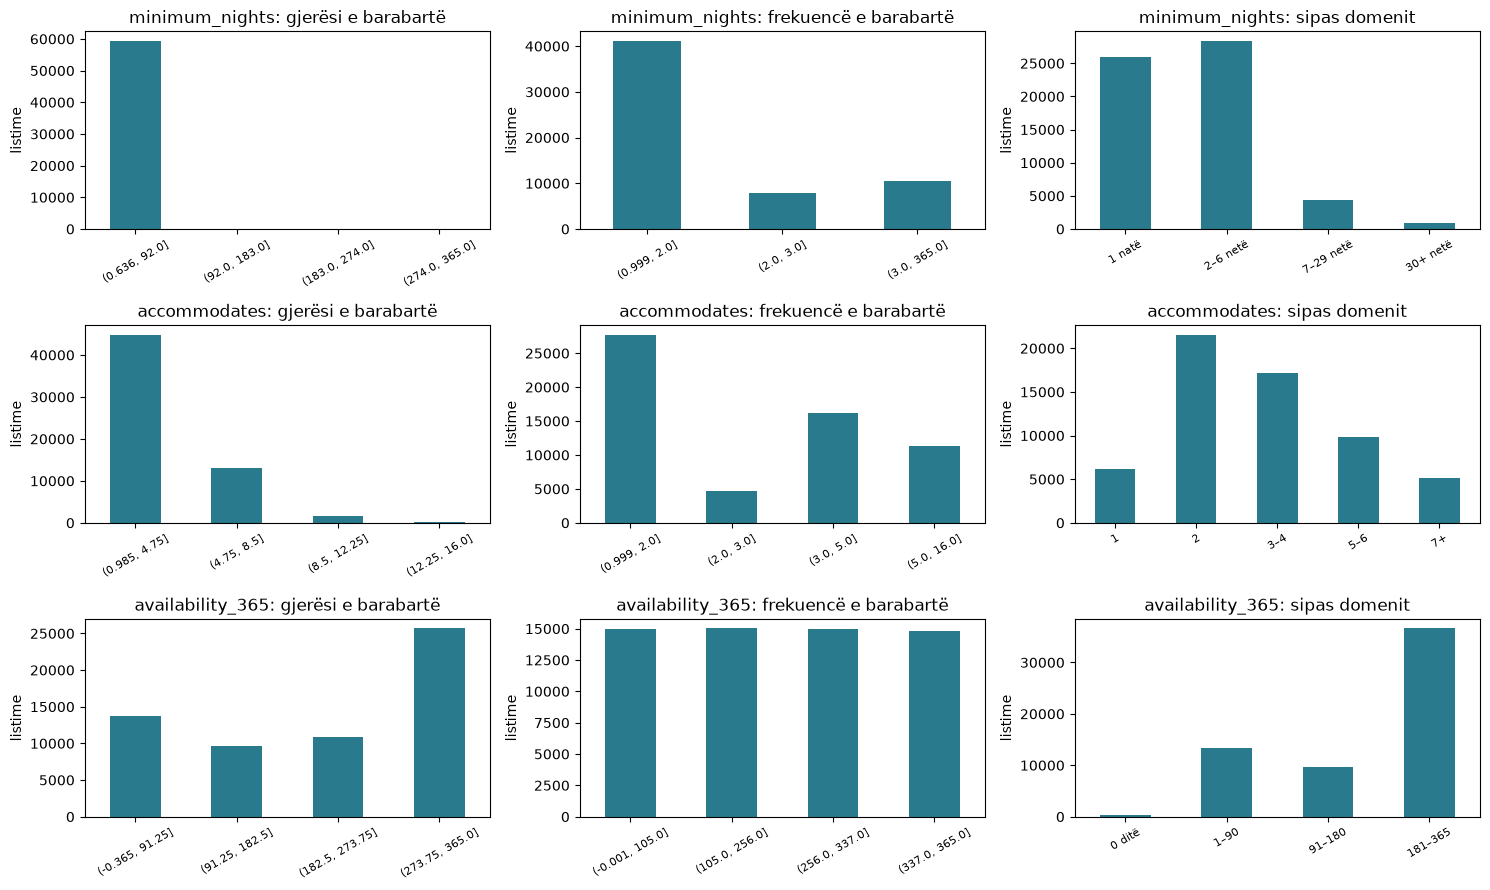

In [11]:
DOMAIN_BINS = {
    "minimum_nights": ([0, 1, 6, 29, np.inf], ["1 natë", "2–6 netë", "7–29 netë", "30+ netë"]),
    "accommodates": ([0, 1, 2, 4, 6, np.inf], ["1", "2", "3–4", "5–6", "7+"]),
    "availability_365": ([-1, 0, 90, 180, 365], ["0 ditë", "1–90", "91–180", "181–365"]),
}
binned = {}
for col, (edges, labels) in DOMAIN_BINS.items():
    binned[col] = {
        "gjerësi e barabartë": pd.cut(df[col], bins=4),
        "frekuencë e barabartë": pd.qcut(df[col], q=4, duplicates="drop"),
        "sipas domenit": pd.cut(df[col], bins=edges, labels=labels),
    }
    df[f"{col}_cat"] = binned[col]["sipas domenit"]

summary = pd.DataFrame([
    {"kolona": col, "metoda": method, "grupe": values.cat.categories.size,
     "grupi më i madh (%)": round(values.value_counts(normalize=True).max() * 100, 1), "bosh": int(values.isna().sum())}
    for col, methods in binned.items() for method, values in methods.items()
]).set_index(["kolona", "metoda"])
display(summary)

fig, axes = plt.subplots(len(binned), 3, figsize=(15, 9))
for row, (col, methods) in zip(axes, binned.items()):
    for ax, (method, values) in zip(row, methods.items()):
        values.value_counts(sort=False).plot.bar(ax=ax, color="#287a8c")
        ax.set(title=f"{col}: {method}", xlabel="", ylabel="listime")
        ax.tick_params(axis="x", rotation=30, labelsize=8)
plt.tight_layout()
plt.show()

**Cila metodë?** Te kolonat shumë asimetrike, gjerësia e barabartë fut pothuajse të gjitha listimet në grupin e parë. Frekuenca e barabartë humbet grupe kur shumë listime kanë të njëjtën vlerë (p.sh. `minimum_nights` = 1). Te `availability_365`, që nuk është asimetrike, gjerësia e barabartë funksionon mirë, ndërsa grupet sipas domenit janë më pak të balancuara (shumica e listimeve kanë mbi 180 ditë të lira). Prandaj si veti finale ruajmë **grupet sipas domenit** (`*_cat`) për shkak të kuptimit, jo të balancës: kufijtë (1 natë, 30+ netë, 90 ditë) kanë kuptim praktik dhe nuk varen nga shpërndarja e këtij dataset-i. Tabela më poshtë tregon çmimin median për secilin grup, si kontroll përshkrues.

In [12]:
for col in DOMAIN_BINS:
    display(df.groupby(f"{col}_cat", observed=True)["price"].agg(listime="size", cmimi_median="median").round(2))

,listime,cmimi_median
minimum_nights_cat,,
1 natë,25875,150.00
2–6 netë,28402,196.69
7–29 netë,4343,170.10
30+ netë,928,128.39


,listime,cmimi_median
accommodates_cat,,
1,6172,65.00
2,21573,118.00
3–4,17122,205.00
5–6,9791,280.00
7+,5188,365.58


,listime,cmimi_median
availability_365_cat,,
0 ditë,305,153.33
1–90,13307,158.57
91–180,9612,178.50
181–365,36622,180.00


### `price_band` si bazë krahasimi

`price_band` u krijua në notebook-un 02 me **frekuencë të barabartë** (tercile të çmimit): tri grupe me afërsisht të njëjtin numër listimesh. E ruajmë si shembull të diskretizimit të çmimit. **Kujdes:** është krijuar nga çmimi, ndaj nuk përdoret si hyrje e modelit kur parashikohet çmimi.

In [13]:
band_order = ["i ulët", "mesatar", "i lartë"]
display(df.groupby("price_band")["price"].agg(listime="size", min="min", max="max").reindex(band_order))

,listime,min,max
price_band,,,
i ulët,19981,10.00,123.0
mesatar,19923,123.02,237.0
i lartë,19942,237.07,6798.4


**Vazhdon:** diskretizimi, binarizimi dhe kodimi.